# ARQ-FEC PoC Analysis

Evaluates the effectiveness of XOR-based FEC with ARQ retransmissions
in the Stream Encoding Geometry (SCHC-over-DTS-IoT) scenario.

**Three outcomes per iteration:**
- FEC sufficed alone (decoded before retransmission, RCS passed)
- ARQ rescued it (FEC failed, but retransmission fixed it)
- Failed (retransmission also failed)

---

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load Data

In [5]:
def load_stats(files=None, pattern="data/stats_*.csv"):
    """Load one or more CSV files into a single DataFrame.

    Parameters
    ----------
    files : list of str or None
        Explicit file paths. If None, loads all files matching `pattern`.
    pattern : str
        Glob used when `files` is None (stream: data/stats_*.csv,
        matrix: data/stats-matrix_*.csv).
    """
    if files is None:
        files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError("No CSV files found.")

    dfs = []
    for f in files:
        d = pd.read_csv(f)
        d["source_file"] = f
        dfs.append(d)

    df = pd.concat(dfs, ignore_index=True)
    print(f"Loaded {len(df):,} iterations across {len(files)} file(s)")
    return df


df = load_stats()
# df = load_stats(pattern="data/stats-matrix_*.csv")  # matrix geometry
# df = load_stats(["stats_2026-05-26_15-08-30.csv"])  # explicit list
df.head(3)

Loaded 72 iterations across 7 file(s)


,iteration,timestamp,cfg_loss_probability,cfg_allow_all1_loss,dev_regular_count,dev_regular_tx_attempts,dev_regular_lost,dev_all1_lost,dev_c1_recvd,dev_c0_recvd,...,srv_regular_recvd,srv_all1_recvd,srv_c1_sent,srv_c0_sent,srv_ackreq_recvd,srv_retx_called,srv_decodeable_before_retx,srv_decodeable,srv_rcs_ok,source_file
0,1,2026-05-26 15:08:30.707921,0.1,True,6,6,1,0,1,0,...,5,True,1,0,0,False,True,True,True,data/stats_2026-05-26_15-08-30.csv
1,2,2026-05-26 15:08:30.835983,0.1,True,6,6,0,0,1,0,...,6,True,1,0,0,False,True,True,True,data/stats_2026-05-26_15-08-30.csv
2,3,2026-05-26 15:08:30.949653,0.1,True,6,6,1,0,1,0,...,5,True,1,0,0,False,True,True,True,data/stats_2026-05-26_15-08-30.csv


## 2. Derived Columns

Expose attempt outcome and FEC/ARQ contribution from raw stats.

In [6]:
# --- Outcome ---
# success_on_attempt: 0=failed, 1=first try, 2=after retransmission
cond = [
    (df["srv_rcs_ok"] == True) & (df["srv_retx_called"] == False),
    (df["srv_rcs_ok"] == True) & (df["srv_retx_called"] == True),
]
df["success_on_attempt"] = np.select(cond, [1, 2], default=0)

# --- Category ---
cond = [
    (df["srv_decodeable_before_retx"] == True) & (df["srv_rcs_ok"] == True)
        & (df["srv_retx_called"] == False),
    (df["srv_rcs_ok"] == True) & (df["srv_retx_called"] == True),
]
df["category"] = np.select(cond, ["FEC sufficed", "ARQ rescued"], default="Failed")

# --- Retransmission cost ---
df["retx_frags"] = df["dev_regular_tx_attempts"] - df["dev_regular_count"]
df["retx_frags_lost"] = df["dev_regular_lost"] - (
    df["dev_regular_tx_attempts"] - df["dev_regular_count"]
    - (df["dev_regular_tx_attempts"] - df["dev_regular_lost"]
       - df["dev_regular_count"])
)
df["actual_loss"] = df["dev_regular_lost"] / df["dev_regular_tx_attempts"]
df["all1_lost_scenario"] = df["dev_all1_lost"] > 0

cols = ["iteration", "success_on_attempt", "category",
        "cfg_loss_probability", "cfg_allow_all1_loss",
        "dev_regular_count", "dev_regular_tx_attempts", "retx_frags",
        "actual_loss", "all1_lost_scenario", "source_file"]
df[cols].head(10)

,iteration,success_on_attempt,category,cfg_loss_probability,cfg_allow_all1_loss,dev_regular_count,dev_regular_tx_attempts,retx_frags,actual_loss,all1_lost_scenario,source_file
0,1,1,FEC sufficed,0.1,True,6,6,0,0.166667,False,data/stats_2026-05-26_15-08-30.csv
1,2,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv
2,3,1,FEC sufficed,0.1,True,6,6,0,0.166667,False,data/stats_2026-05-26_15-08-30.csv
3,4,2,ARQ rescued,0.1,True,6,8,2,0.250000,False,data/stats_2026-05-26_15-08-30.csv
4,5,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv
5,6,2,FEC sufficed,0.1,True,6,8,2,0.250000,False,data/stats_2026-05-26_15-08-30.csv
6,7,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv
7,8,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv
8,9,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv
9,10,1,FEC sufficed,0.1,True,6,6,0,0.000000,False,data/stats_2026-05-26_15-08-30.csv


## 3. Overall Summary

In [7]:
total = len(df)
print(f"Total iterations        : {total}")
print(f"Config loss probability : {df['cfg_loss_probability'].unique()}")
print(f"Allow All-1 loss        : {df['cfg_allow_all1_loss'].unique()}")
print()
print(f"Success rate            : {df['success_on_attempt'].gt(0).mean():.1%}")
print(f"  └ First try           : {(df['success_on_attempt']==1).mean():.1%}")
print(f"  └ After retx          : {(df['success_on_attempt']==2).mean():.1%}")
print(f"Failure rate            : {(df['success_on_attempt']==0).mean():.1%}")
print()
print("--- Category breakdown ---")
print(df["category"].value_counts().to_string())

Total iterations        : 72
Config loss probability : [0.1  0.15 0.2  0.25 0.3  0.4  0.5 ]
Allow All-1 loss        : [ True]

Success rate            : 79.2%
  └ First try           : 59.7%
  └ After retx          : 19.4%
Failure rate            : 20.8%

--- Category breakdown ---
category
FEC sufficed    49
Failed          15
ARQ rescued      8


## 4. FEC Effectiveness

**FEC sufficed** = XOR parity recovered all missing symbols on first pass.
No retransmission needed. This is the ideal case.

**ARQ rescued** = first pass failed (not decodeable or bad RCS),
but C=0 trigger + retransmission provided enough symbols.

**Failed** = neither mechanism delivered a valid SCHC packet.

category
FEC sufficed    49
Failed          15
ARQ rescued      8

  FEC sufficed        49  ( 68.1%)
  Failed              15  ( 20.8%)
  ARQ rescued          8  ( 11.1%)


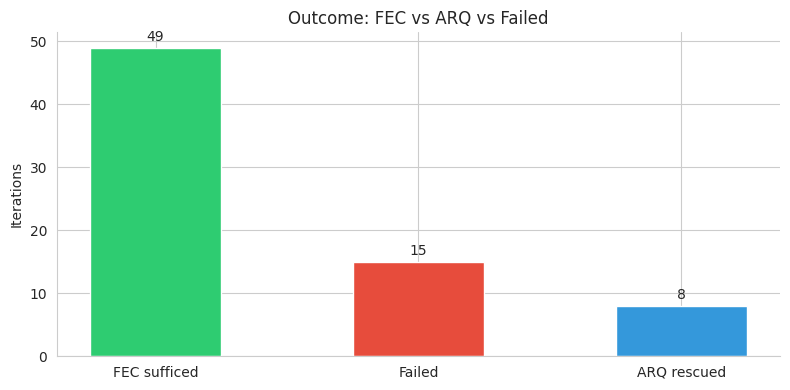

In [8]:
cats = df["category"].value_counts()
print(cats.to_string())
print()
for label, count in cats.items():
    print(f"  {label:16s}  {count:4d}  ({count/total:6.1%})")

fig, ax = plt.subplots()
colors = {"FEC sufficed": "#2ecc71", "ARQ rescued": "#3498db", "Failed": "#e74c3c"}
bars = ax.bar(cats.index, cats.values, color=[colors[c] for c in cats.index],
              edgecolor="white", width=0.5)
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_ylabel("Iterations")
ax.set_title("Outcome: FEC vs ARQ vs Failed")
sns.despine()
plt.tight_layout()
plt.show()

## 5. Breakdown by Loss Probability

In [9]:
grouped = df.groupby("cfg_loss_probability").agg(
    total=("success_on_attempt", "count"),
    success_rate=("success_on_attempt", lambda x: x.gt(0).mean()),
    fec_only=("category", lambda x: (x == "FEC sufficed").mean()),
    arq_rescue=("category", lambda x: (x == "ARQ rescued").mean()),
    failed=("category", lambda x: (x == "Failed").mean()),
    avg_retx_frags=("retx_frags", "mean"),
    avg_actual_loss=("actual_loss", "mean"),
    all1_lost_rate=("all1_lost_scenario", "mean"),
).round(4)
grouped

,total,success_rate,fec_only,arq_rescue,failed,avg_retx_frags,avg_actual_loss,all1_lost_rate
cfg_loss_probability,,,,,,,,
0.10,12,1.0,0.9167,0.0833,0.0,0.4167,0.0813,0.1667
0.15,10,0.9,0.9000,0.0000,0.1,0.5000,0.2101,0.2000
0.20,10,0.8,0.7000,0.1000,0.2,0.2000,0.1083,0.2000
0.25,10,0.7,0.5000,0.2000,0.3,1.1000,0.1952,0.5000
0.30,10,0.9,0.7000,0.2000,0.1,1.7000,0.2819,0.4000
0.40,10,0.8,0.6000,0.2000,0.2,2.5000,0.4056,0.4000
0.50,10,0.4,0.4000,0.0000,0.6,2.2000,0.4153,0.5000


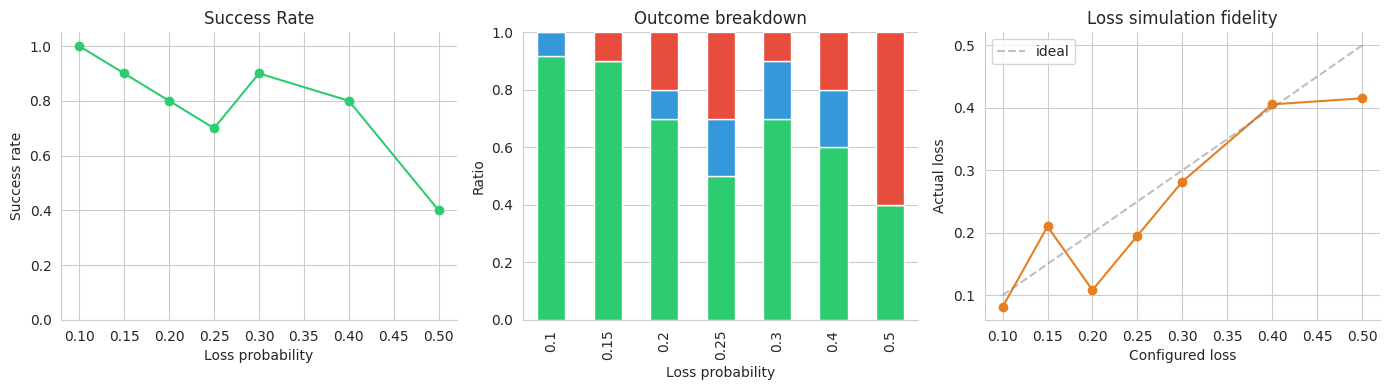

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Success rate
axes[0].plot(grouped.index, grouped["success_rate"], "o-", color="#2ecc71")
axes[0].set_xlabel("Loss probability")
axes[0].set_ylabel("Success rate")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Success Rate")

# Stacked bar: FEC vs ARQ vs Failed
grouped[["fec_only", "arq_rescue", "failed"]].plot.bar(
    ax=axes[1], stacked=True,
    color=["#2ecc71", "#3498db", "#e74c3c"],
    edgecolor="white", legend=False
)
axes[1].set_xlabel("Loss probability")
axes[1].set_ylabel("Ratio")
axes[1].set_title("Outcome breakdown")

# Actual vs configured loss
axes[2].plot(grouped.index, grouped["avg_actual_loss"], "o-", color="#e67e22")
axes[2].plot(grouped.index, grouped.index, "--", color="gray", alpha=0.5, label="ideal")
axes[2].set_xlabel("Configured loss")
axes[2].set_ylabel("Actual loss")
axes[2].set_title("Loss simulation fidelity")
axes[2].legend()

sns.despine()
plt.tight_layout()
plt.show()

## 6. All-1 Loss Scenarios

When All-1 is lost, the server never gets RCS + trailing symbols.
The device times out and resends the All-1 (each All-1 / ACK-REQ sent
counts towards `MAX_ATTEMPTS`).

In [11]:
ackreq = df[df["all1_lost_scenario"]]
no_ackreq = df[~df["all1_lost_scenario"]]

if len(ackreq) > 0:
    print(f"All-1 lost: {len(ackreq)} / {len(df)} iterations")
    print()
    print("  All-1 never lost:")
    print(f"    Success: {no_ackreq['success_on_attempt'].gt(0).mean():.1%}")
    print(f"    Retx needed: {no_ackreq['srv_retx_called'].mean():.1%}")
    print()
    print("  All-1 lost at least once:")
    print(f"    Success: {ackreq['success_on_attempt'].gt(0).mean():.1%}")
    print(f"    Retx needed: {ackreq['srv_retx_called'].mean():.1%}")
    print()
    print("  All-1 loss scenario rows:")
    display(ackreq[["iteration", "cfg_loss_probability",
                   "success_on_attempt", "category",
                   "srv_retx_called", "srv_decodeable_before_retx",
                   "dev_attempts", "source_file"]])
else:
    print("No All-1 loss scenarios in this dataset.")
    print("(Set cfg_allow_all1_loss = True with sufficient iterations to see them.)")

ACK-REQ triggered: 24 / 72 iterations

  Without ACK-REQ:
    Success: 93.8%
    Retx needed: 35.4%

  With ACK-REQ:
    Success: 50.0%
    Retx needed: 0.0%

  All-1 loss scenario rows:


,iteration,cfg_loss_probability,success_on_attempt,category,srv_retx_called,srv_decodeable_before_retx,dev_attempts,source_file
10,11,0.10,1,FEC sufficed,False,True,2,data/stats_2026-05-26_15-08-30.csv
11,12,0.10,1,FEC sufficed,False,True,2,data/stats_2026-05-26_15-08-30.csv
17,6,0.15,1,FEC sufficed,False,True,2,data/stats_2026-05-26_15-39-06.csv
20,9,0.15,0,Failed,False,True,2,data/stats_2026-05-26_15-39-06.csv
26,5,0.20,0,Failed,False,True,2,data/stats_2026-05-26_15-39-38.csv
30,9,0.20,0,Failed,False,True,2,data/stats_2026-05-26_15-39-38.csv
33,2,0.25,1,FEC sufficed,False,True,2,data/stats_2026-05-26_15-40-15.csv
34,3,0.25,1,FEC sufficed,False,True,2,data/stats_2026-05-26_15-40-15.csv
35,4,0.25,0,Failed,False,True,2,data/stats_2026-05-26_15-40-15.csv
37,6,0.25,0,Failed,False,True,2,data/stats_2026-05-26_15-40-15.csv


## 7. Retransmission Overhead

How many extra fragments were sent beyond the baseline (`dev_regular_count`)?

In [12]:
print("Average overhead per iteration:")
print(f"  Baseline fragments     : {df['dev_regular_count'].mean():.1f}")
print(f"  Total TX attempts      : {df['dev_regular_tx_attempts'].mean():.1f}")
print(f"  Retransmitted frags    : {df['retx_frags'].mean():.1f}")
print(f"  Lost frags per attempt : {df['dev_regular_lost'].mean():.1f}")
print()
print("By loss probability:")
overhead = df.groupby("cfg_loss_probability").agg({
    "dev_regular_count": "mean",
    "dev_regular_tx_attempts": "mean",
    "retx_frags": "mean",
    "dev_regular_lost": "mean",
}).round(2)
overhead

Average overhead per iteration:
  Baseline fragments     : 6.0
  Total TX attempts      : 7.2
  Retransmitted frags    : 1.2
  Lost frags per attempt : 1.9

By loss probability:


,dev_regular_count,dev_regular_tx_attempts,retx_frags,dev_regular_lost
cfg_loss_probability,,,,
0.10,6.0,6.42,0.42,0.58
0.15,6.0,6.50,0.50,1.40
0.20,6.0,6.20,0.20,0.70
0.25,6.0,7.10,1.10,1.50
0.30,6.0,7.70,1.70,2.30
0.40,6.0,8.50,2.50,3.60
0.50,6.0,8.20,2.20,3.80


## 8. Failure Drill-Down

Rows where success_on_attempt == 0.

In [13]:
failures = df[df["success_on_attempt"] == 0]
if len(failures) > 0:
    print(f"Failure count: {len(failures)}")
    display(failures[["iteration", "cfg_loss_probability",
                     "srv_decodeable", "srv_all1_recvd",
                     "srv_retx_called", "all1_lost_scenario",
                     "dev_regular_lost", "dev_regular_tx_attempts",
                     "source_file"]])
else:
    print("No failures.")

Failure count: 15


,iteration,cfg_loss_probability,srv_decodeable,srv_all1_recvd,srv_retx_called,all1_lost_scenario,dev_regular_lost,dev_regular_tx_attempts,source_file
20,9,0.15,True,False,False,True,3,8,data/stats_2026-05-26_15-39-06.csv
26,5,0.20,True,False,False,True,0,6,data/stats_2026-05-26_15-39-38.csv
30,9,0.20,True,False,False,True,0,6,data/stats_2026-05-26_15-39-38.csv
35,4,0.25,True,False,False,True,1,7,data/stats_2026-05-26_15-40-15.csv
37,6,0.25,True,False,False,True,2,8,data/stats_2026-05-26_15-40-15.csv
38,7,0.25,True,False,False,True,3,8,data/stats_2026-05-26_15-40-15.csv
47,6,0.30,True,False,False,True,0,6,data/stats_2026-05-26_15-41-00.csv
58,7,0.40,False,True,True,False,5,9,data/stats_2026-05-26_15-41-30.csv
60,9,0.40,True,False,False,True,5,10,data/stats_2026-05-26_15-41-30.csv
62,1,0.50,True,False,False,True,1,7,data/stats_2026-05-26_15-42-06.csv


## 9. Config Distribution

Quick check: what configurations are present in the loaded dataset?

In [14]:
print("Configurations present:")
group_cols = ["cfg_loss_probability", "cfg_allow_all1_loss"]
configs = df.groupby(group_cols).size().reset_index(name="iterations")
configs

Configurations present:


,cfg_loss_probability,cfg_allow_all1_loss,iterations
0,0.10,True,12
1,0.15,True,10
2,0.20,True,10
3,0.25,True,10
4,0.30,True,10
5,0.40,True,10
6,0.50,True,10


## 10. Source Files

Confirm which files contributed data.

In [15]:
print(df["source_file"].value_counts().to_string())

source_file
data/stats_2026-05-26_15-08-30.csv    12
data/stats_2026-05-26_15-39-06.csv    10
data/stats_2026-05-26_15-39-38.csv    10
data/stats_2026-05-26_15-40-15.csv    10
data/stats_2026-05-26_15-41-00.csv    10
data/stats_2026-05-26_15-41-30.csv    10
data/stats_2026-05-26_15-42-06.csv    10
